# NYC Yellow Taxi — January 2024 Analysis

Runs SQL against `~/demo_taxi.duckdb` (read-only) and charts the answers to the running questions:

1. How many trips are in the database and what date range do they cover?
2. What's the busiest hour of the day for pickups?
3. Top 5 pickup neighbourhoods
4. Which borough has the most dropoffs?
5. JFK → Manhattan: volume and average cost

Notes: the table holds ~2.96M rows spanning 2003–2024, but essentially all activity is January 2024. A handful of rows carry stray dates and zero/negative fares, so time-based and money-based aggregates filter to `2024-01-01`–`2024-01-31` and `total_amount > 0`.

In [9]:
import os
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

con = duckdb.connect(os.path.expanduser("~/demo_taxi.duckdb"), read_only=True)

JAN = "tpep_pickup_datetime BETWEEN '2024-01-01' AND '2024-01-31 23:59:59'"

def q(sql):
    return con.sql(sql).df()

## 1. Scale & date range (and trips over time)

The database holds **~2.96M trips** with pickup timestamps nominally spanning 2002-12-31 to 2024-02-01. Just 18 of those rows fall outside January 2024, so the effective coverage is the month of **January 2024 (31 days)**. Below: the raw daily curve across the whole table (log scale — the pre-2024 dates are a trivial tail), then the January daily volume on a linear scale.

In [10]:
summary = q("""
    SELECT count(*) AS total_trips,
           min(tpep_pickup_datetime)::DATE AS first_pickup,
           max(tpep_pickup_datetime)::DATE AS last_pickup,
           count(*) FILTER (WHERE tpep_pickup_datetime NOT BETWEEN '2024-01-01' AND '2024-01-31 23:59:59')
             AS rows_outside_jan_2024
    FROM trips
""")
summary["avg_total_amount"] = q(
    f"SELECT round(avg(total_amount), 2) AS a FROM trips WHERE {JAN} AND total_amount > 0"
)["a"][0]
summary["avg_trip_miles"] = q(f"SELECT round(avg(trip_distance), 1) AS a FROM trips WHERE {JAN}")["a"][0]
summary

,total_trips,first_pickup,last_pickup,rows_outside_jan_2024,avg_total_amount,avg_trip_miles
0,2964624,2002-12-31,2024-02-01,18,27.44,3.7


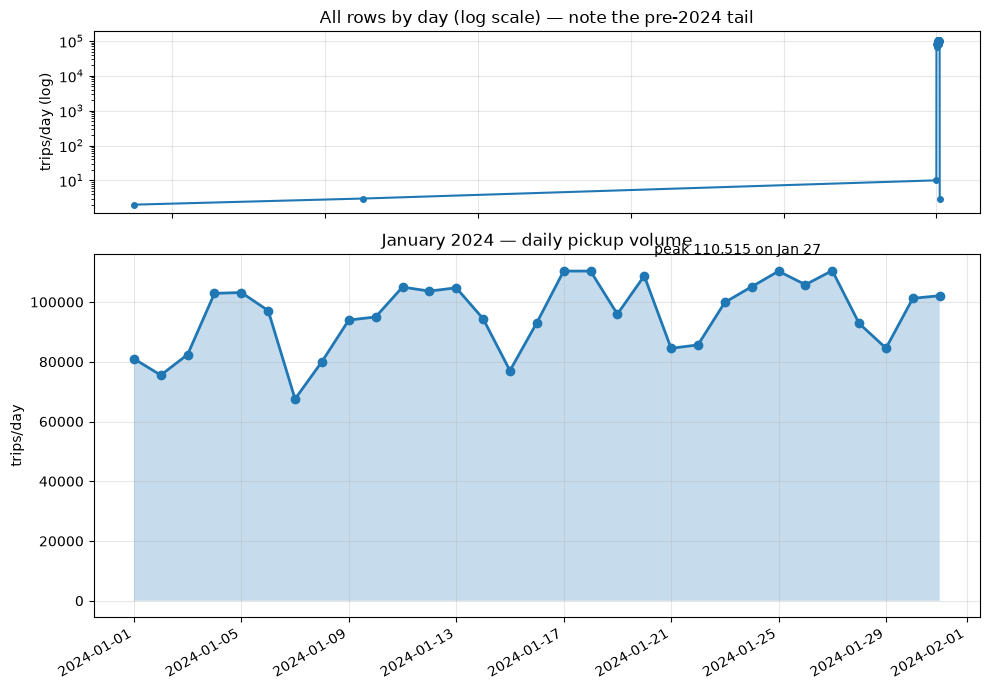

In [11]:
daily = q(f"""
    SELECT date_trunc('day', tpep_pickup_datetime)::DATE AS day,
           count(*) AS pickups
    FROM trips
    GROUP BY 1 ORDER BY 1
""")

fig, axes = plt.subplots(2, 1, figsize=(10, 7), height_ratios=[1, 2])

axes[0].semilogy(daily["day"], daily["pickups"], marker="o", ms=4)
axes[0].set_title("All rows by day (log scale) — note the pre-2024 tail")
axes[0].set_ylabel("trips/day (log)")

jan = daily[daily["day"].between("2024-01-01", "2024-01-31")]
axes[1].fill_between(jan["day"], jan["pickups"], alpha=0.25)
axes[1].plot(jan["day"], jan["pickups"], marker="o", lw=2)
peak = jan.loc[jan["pickups"].idxmax()]
axes[1].annotate(f'peak {peak["pickups"]:,} on {peak["day"]:%b %d}',
                 xy=(peak["day"], peak["pickups"]), xytext=(-8, 12),
                 textcoords="offset points", ha="right")
axes[1].set_title("January 2024 — daily pickup volume")
axes[1].set_ylabel("trips/day")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

## 2. Busiest hour of the day

Grouping pickups by hour (`hour(tpep_pickup_datetime)`, Jan 2024 only). The busiest hour is **18:00 (6 pm)** — the evening commute peak, with 17:00 a close second. The heatmap underneath shows how the hourly profile varies by weekday, and the line chart tracks the 6 pm peak over the month.

Top 5 pickup hours (Jan 2024):


,hour,pickups
18,18:00,212788
17,17:00,206257
16,16:00,190201
15,15:00,189359
19,19:00,184032


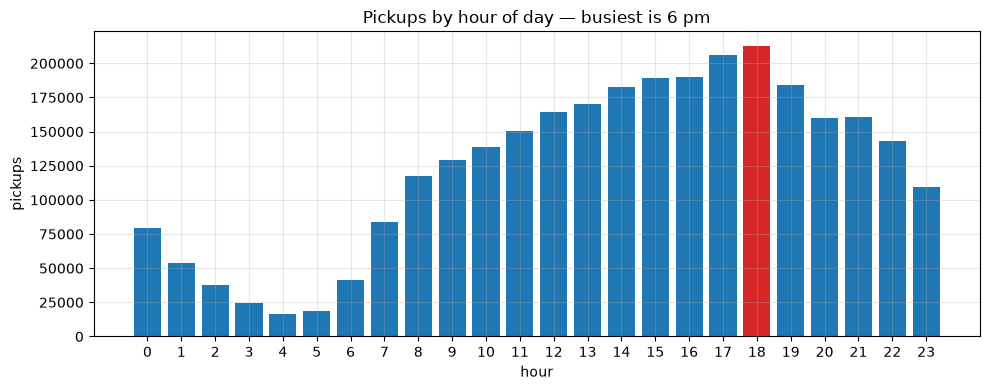

In [12]:
hourly = q(f"""
    SELECT EXTRACT(hour FROM tpep_pickup_datetime)::INT AS hour,
           count(*) AS pickups
    FROM trips
    WHERE {JAN}
    GROUP BY 1 ORDER BY 1
""")
top_hours = hourly.sort_values("pickups", ascending=False).head(5)
print("Top 5 pickup hours (Jan 2024):")
display(top_hours.assign(hour=lambda d: d["hour"].map("{:02d}:00".format)))

fig, ax = plt.subplots(figsize=(10, 4))
colors = ["#d62728" if h == hourly.loc[hourly["pickups"].idxmax(), "hour"]
          else "#1f77b4" for h in hourly["hour"]]
ax.bar(hourly["hour"], hourly["pickups"], color=colors)
ax.set_xticks(range(0, 24))
ax.set_title("Pickups by hour of day — busiest is 6 pm")
ax.set_xlabel("hour"); ax.set_ylabel("pickups")
fig.tight_layout(); plt.show()

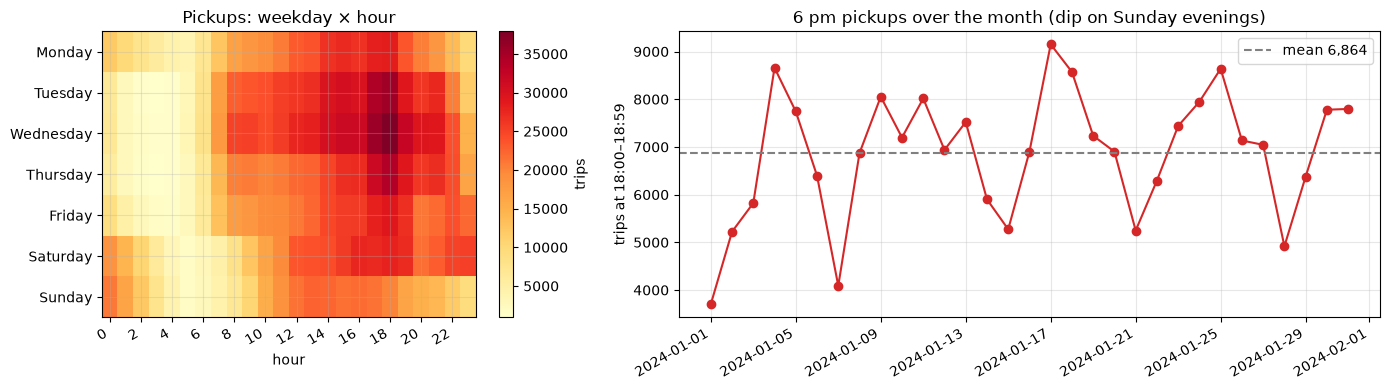

In [13]:
hour_dow = q(f"""
    SELECT EXTRACT(hour FROM tpep_pickup_datetime)::INT AS hour,
           dayname(tpep_pickup_datetime) AS dow,
           count(*) AS n
    FROM trips WHERE {JAN} GROUP BY 1, 2
""")
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
pivot = (hour_dow.assign(dow=pd.Categorical(hour_dow["dow"], order))
                   .pivot_table(index="dow", columns="hour", values="n", observed=True))

peak18 = q(f"""
    SELECT date_trunc('day', tpep_pickup_datetime)::DATE AS day,
           count(*) AS evening_pickups
    FROM trips WHERE {JAN} AND EXTRACT(hour FROM tpep_pickup_datetime) = 18
    GROUP BY 1 ORDER BY 1
""")

fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2, 3]})
im = axes[0].imshow(pivot.values, aspect="auto", cmap="YlOrRd")
axes[0].set_xticks(range(0, 24, 2)); axes[0].set_xticklabels(range(0, 24, 2))
axes[0].set_yticks(range(len(pivot))); axes[0].set_yticklabels(pivot.index)
axes[0].set_title("Pickups: weekday × hour"); axes[0].set_xlabel("hour")
fig.colorbar(im, ax=axes[0], label="trips")

axes[1].plot(peak18["day"], peak18["evening_pickups"], marker="o", color="#d62728")
axes[1].set_title("6 pm pickups over the month (dip on Sunday evenings)")
axes[1].set_ylabel("trips at 18:00–18:59")
axes[1].axhline(peak18["evening_pickups"].mean(), ls="--", c="gray",
                label=f'mean {peak18["evening_pickups"].mean():,.0f}')
axes[1].legend()
fig.autofmt_xdate(); fig.tight_layout(); plt.show()

## 3. Top 5 pickup neighbourhoods

Joining `trips.PULocationID → zones.LocationID` (Jan 2024). **JFK Airport** leads, with four Manhattan zones behind it — and the trend lines show JFK's volume is far spikier than the steady Manhattan zones.

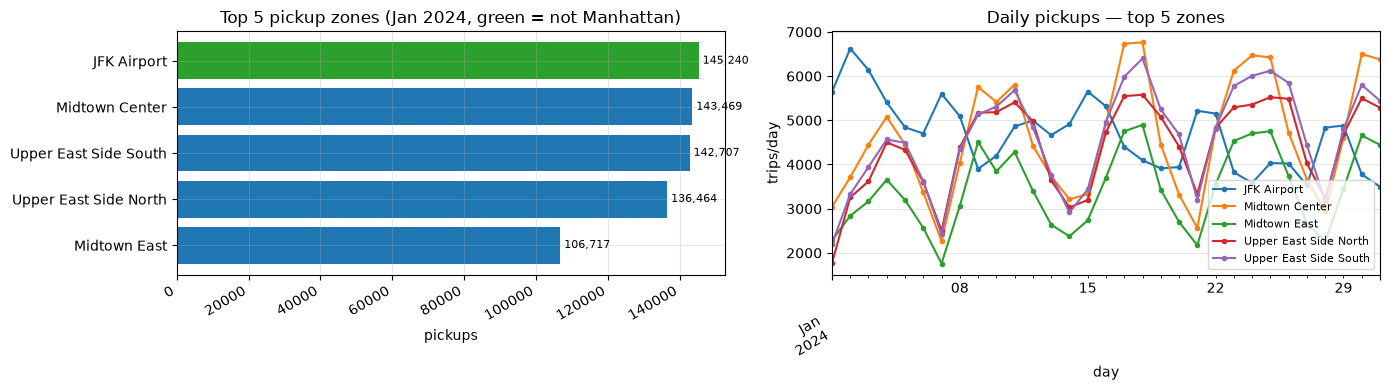

In [14]:
top_zones = q(f"""
    SELECT z.Borough, z.Zone, count(*) AS trips
    FROM trips t JOIN zones z ON z.LocationID = t.PULocationID
    WHERE {JAN}
    GROUP BY 1, 2 ORDER BY trips DESC LIMIT 5
""")
top_zones

zone_daily = q(f"""
    WITH top5 AS (
        SELECT PULocationID AS lid
        FROM trips WHERE {JAN}
        GROUP BY 1 ORDER BY count(*) DESC LIMIT 5
    )
    SELECT date_trunc('day', t.tpep_pickup_datetime)::DATE AS day,
           z.Zone, count(*) AS n
    FROM trips t
    JOIN zones z ON z.LocationID = t.PULocationID
    WHERE {JAN} AND t.PULocationID IN (SELECT lid FROM top5)
    GROUP BY 1, 2 ORDER BY 1
""")
zp = zone_daily.pivot_table(index="day", columns="Zone", values="n")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
zb = top_zones.sort_values("trips")
axes[0].barh(zb["Zone"], zb["trips"],
             color=["#2ca02c" if b == "Queens" else "#1f77b4" for b in zb["Borough"]])
for y, (v, b) in enumerate(zip(zb["trips"], zb["Borough"])):
    axes[0].text(v, y, f" {v:,}", va="center", fontsize=8)
axes[0].set_title("Top 5 pickup zones (Jan 2024, green = not Manhattan)")
axes[0].set_xlabel("pickups")

zp.plot(ax=axes[1], marker="o", ms=3, lw=1.5)
axes[1].set_title("Daily pickups — top 5 zones")
axes[1].set_ylabel("trips/day"); axes[1].legend(fontsize=8)
fig.autofmt_xdate(); fig.tight_layout(); plt.show()

## 4. Borough with the most dropoffs

**Manhattan** dominates with ~2.66M dropoffs — about 18× Queens. The daily trend (log scale, since Brooklyn/Bronx are two to three orders of magnitude smaller) shows Manhattan driving nearly all of the weekday/weekend rhythm.

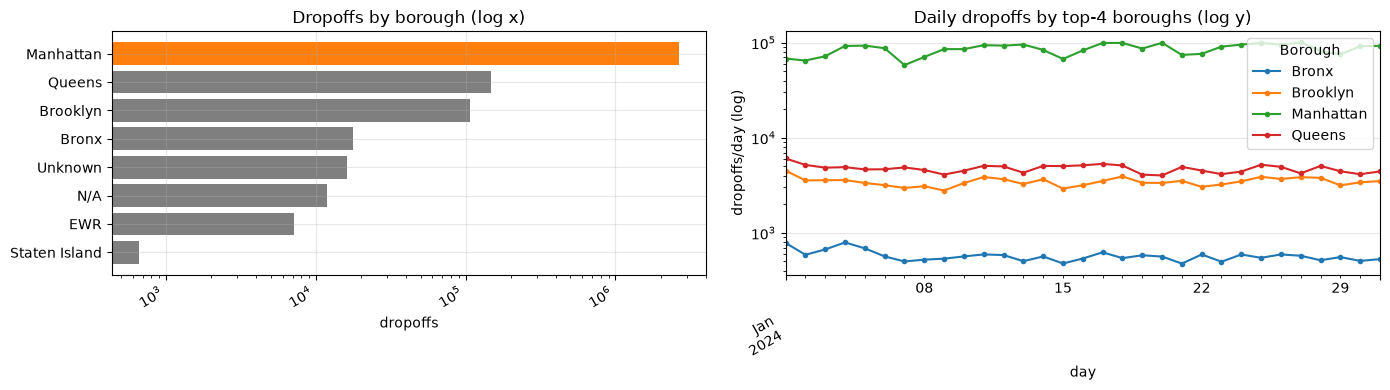

In [15]:
boroughs = q(f"""
    SELECT z.Borough, count(*) AS dropoffs
    FROM trips t JOIN zones z ON z.LocationID = t.DOLocationID
    WHERE {JAN}
    GROUP BY 1 ORDER BY dropoffs DESC
""")
boroughs

boro_daily = q(f"""
    SELECT date_trunc('day', t.tpep_pickup_datetime)::DATE AS day,
           z.Borough, count(*) AS n
    FROM trips t JOIN zones z ON z.LocationID = t.DOLocationID
    WHERE {JAN}
    GROUP BY 1, 2
""")
keep = boroughs.head(4)["Borough"].tolist()
bd = (boro_daily[boro_daily["Borough"].isin(keep)]
      .pivot_table(index="day", columns="Borough", values="n"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
bb = boroughs.sort_values("dropoffs")
axes[0].barh(bb["Borough"], bb["dropoffs"],
             color=["#ff7f0e" if b == "Manhattan" else "#7f7f7f" for b in bb["Borough"]])
axes[0].set_xscale("log")
axes[0].set_title("Dropoffs by borough (log x)")
axes[0].set_xlabel("dropoffs")

bd.plot(ax=axes[1], marker="o", ms=3, lw=1.5)
axes[1].set_yscale("log")
axes[1].set_title("Daily dropoffs by top-4 boroughs (log y)")
axes[1].set_ylabel("dropoffs/day (log)")
fig.autofmt_xdate(); fig.tight_layout(); plt.show()

## 5. JFK → Manhattan

Using the skill's template: pickup zone `JFK Airport`, dropoff borough `Manhattan`, Jan 2024, guarding with `tpep_dropoff_datetime > tpep_pickup_datetime` and `total_amount > 0` for the averages. ~71.4k trips at an average total of ~$94.4 (vs ~$27.4 for the average January trip — it's a long cross-town run).

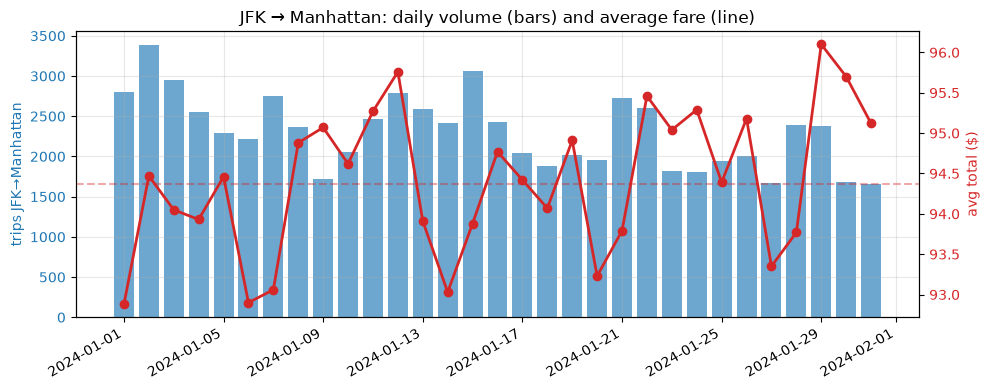

In [16]:
jfk = q(f"""
    SELECT count(*) AS trips,
           round(avg(t.total_amount), 2) AS avg_total,
           round(avg(t.fare_amount), 2)  AS avg_meter,
           round(avg(t.trip_distance), 1) AS avg_miles,
           round(avg(date_diff('minute', t.tpep_pickup_datetime, t.tpep_dropoff_datetime)), 0) AS avg_minutes
    FROM trips t
    JOIN zones pu ON pu.LocationID = t.PULocationID
    JOIN zones d  ON d.LocationID  = t.DOLocationID
    WHERE pu.Zone = 'JFK Airport' AND d.Borough = 'Manhattan'
      AND {JAN}
      AND t.tpep_dropoff_datetime > t.tpep_pickup_datetime
      AND t.total_amount > 0
""")
jfk

jfk_daily = q(f"""
    SELECT date_trunc('day', t.tpep_pickup_datetime)::DATE AS day,
           count(*) AS trips,
           round(avg(t.total_amount), 2) AS avg_total
    FROM trips t
    JOIN zones pu ON pu.LocationID = t.PULocationID
    JOIN zones d  ON d.LocationID  = t.DOLocationID
    WHERE pu.Zone = 'JFK Airport' AND d.Borough = 'Manhattan'
      AND {JAN}
      AND t.tpep_dropoff_datetime > t.tpep_pickup_datetime
      AND t.total_amount > 0
    GROUP BY 1 ORDER BY 1
""")

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(jfk_daily["day"], jfk_daily["trips"], color="#1f77b4", alpha=0.65, label="trips")
ax1.set_ylabel("trips JFK→Manhattan", color="#1f77b4")
ax1.tick_params(axis="y", labelcolor="#1f77b4")

ax2 = ax1.twinx(); ax2.grid(False)
ax2.plot(jfk_daily["day"], jfk_daily["avg_total"], color="#d62728", marker="o", lw=2, label="avg total $")
ax2.set_ylabel("avg total ($)", color="#d62728")
ax2.tick_params(axis="y", labelcolor="#d62728")
ax2.axhline(jfk["avg_total"][0], ls="--", c="#d62728", alpha=0.4)

ax1.set_title("JFK → Manhattan: daily volume (bars) and average fare (line)")
fig.autofmt_xdate(); fig.tight_layout(); plt.show()

## Takeaways

- **~2.96M trips**, effectively all in **January 2024**; ~96k trips/day on average.
- **6 pm is the busiest pickup hour** (~213k), with 5 pm a close second; the weekday × hour heatmap shows a strong Tue–Thu evening peak, Sunday evenings clearly quieter, and Saturday nightlife keeping 10 pm busy.
- **JFK Airport is the #1 pickup zone**, but the top of the map is otherwise Manhattan (Midtown + Upper East Side); Manhattan also absorbs ~90% of all dropoffs.
- **JFK → Manhattan** is a premium lane: ~71.4k trips at ~$94 average total, ~17 miles and ~40 minutes door to door — roughly 3.4× the typical January fare for a stable, predictable price.